playing around ignore this section.

In [ ]:
import skyfield
from skyfield.api import Loader, load, N, W, wgs84
import time

load = Loader('./skyfield-data')

planets = load('de421.bsp')
earth, mars = planets['earth'], planets['mars']

ts = load.timescale()
t = ts.now()
position = earth.at(t).observe(mars)
ra, dec, distance = position.radec()

print(ra)
print(dec)
print(distance)

# Create a timescale and ask the current time.
ts = load.timescale()
t = ts.now()

# Load the JPL ephemeris DE421 (covers 1900-2050).
planets = load('de421.bsp')
earth, mars = planets['earth'], planets['mars']

# What's the position of Mars, viewed from Earth?
astrometric = earth.at(t).observe(mars)
ra, dec, distance = astrometric.radec()

print(ra)
print(dec)
print(distance)

boston = earth + wgs84.latlon(42.3583 * N, 71.0636 * W)
astrometric = boston.at(t).observe(mars)
alt, az, d = astrometric.apparent().altaz()

print(alt)
print(az)

from astropy import units as u
xyz = astrometric.xyz.to(u.au)
altitude = alt.to(u.deg)

print(xyz)
print('{0:0.03f}'.format(altitude))

MY NOTES


skyfield
6 points

make a script that uses skyfrield and orbital data (simulate confirmation is near a ground station that we're using) Then send that confirmiation /flag to alex/avexsta mock sat script to send to yamcs.


write boolean function when current coords are in our desired path.

satilette following? -> use one thats already up (find an orbital path of in range)

range for: 2-8m?

600-2500 km slant range. azimuth 0-360 deg, elevation 0-90




finished product: alex and me both in sync confirmation is at reach and out of reach.
also be able to send conrimation flag to ??? alex's script. an event
a script to change the yamcs to cts be sending empty packets when out of range and then when in range, start sending regular data

grafana
honestly should be done already
<br>



In [19]:
from skyfield.api import EarthSatellite, Loader, load, wgs84
from skyfield.timelib import Time, Timescale
import time
import numpy as np

# stations_url = 'https://celestrak.org/NORAD/elements/gp.php?GROUP=active&FORMAT=tle'
url = 'https://celestrak.org/NORAD/elements/gp.php?CATNR=900&FORMAT=tle'
load = Loader('./skyfield-data')
satellites = load.tle_file(url)
calsphere_1 = satellites[0]
print(f"Loaded {len(satellites)} active satellites")

locations = [
    ("Absheron, Azerbaijan", wgs84.latlon(40.466389, 49.486111)),
    ("Punta Arenas, Chile", wgs84.latlon(-53.041556, -70.846944)),
    ("Santiago, Chile", wgs84.latlon(-33.364639, -70.772250)),
    ("Blönduós, Iceland", wgs84.latlon(65.647194, -20.245111)),
    ("Kandy, Sri Lanka", wgs84.latlon(7.274278, 80.724833)),
    ("Pretoria, South Africa", wgs84.latlon(-25.860306, 28.453750)),
]

ts = load.timescale()

Loaded 1 active satellites


In [ ]:
import os
TLE_URL = 'https://celestrak.org/NORAD/elements/gp.php?CATNR=900&FORMAT=tle'
DATA_DIR = './skyfield-data'
DATA_FILE = 'gp.php'

load = Loader(DATA_DIR)
if os.path.exists(f"{DATA_DIR}/{DATA_FILE}"):
    satellites = load.tle_file(DATA_FILE)
    print("found file!")
else:
    satellites = load.tle_file(TLE_URL)
    print("downloading otherwise")

./skyfield-data/gp.php
found file!


In [ ]:
def find_all_valid_sat(locations: list, satellites: list, total_needed: int = 10) -> list:
    """
    Input: list of locations, list of Skyfield satellites, # of satellites
    Output: list of valid satellite names that hit all locations within 3 days
    """
    ts = load.timescale()
    t0 = ts.now()
    t1 = t0 + 3

    valid_sats = []
    for index, sat in enumerate(satellites):
        inclination_deg = np.degrees(sat.model.inclo)
        if inclination_deg < 65.0:
            continue
            
        visited = set()
        for name, site in locations:
            _, events = sat.find_events(site, t0, t1, altitude_degrees=80.0)
            if len(events) > 0:
                visited.add(name)
            else:
                break

        if len(visited) == len(locations):
            valid_sats.append(sat.name)

        if len(valid_sats) >= total_needed:
            break
            
    return valid_sats

def get_sat_location_at_time(satilette: EarthSatellite, time: Time = None) -> tuple:
    if time is None:
        time = ts.now()
    geocentric = satilette.at(time)
    # Convert position to sub-satellite latitude, longitude, and elevation
    subpoint = wgs84.subpoint(geocentric)
    print(
        f"Time: {time.utc_strftime('%Y-%m-%d %H:%M:%S')} UTC | "
        f"Lat: {subpoint.latitude.degrees:.2f}° | "
        f"Long: {subpoint.longitude.degrees:.2f}° | "
        f"Alt: {subpoint.elevation.km:.1f} km"
    )

    return subpoint.latitude.degrees, subpoint.longitude.degrees

def up_now_fast(satilette: EarthSatellite, locations: list,  t0: Time = None) -> bool:
    if t0 is None:
        t0 = ts.now()

    for _, site in locations:
        difference = satilette - site
        topocentric = difference.at(t0)
        alt, az, distance = topocentric.altaz()
        if alt.degrees >= 10.0:
            #print(f"Pass active! Altitude: {alt.degrees:.2f}° (Azimuth: {az.degrees:.2f}°)")
            return True
    #print(f"No pass. Current altitude is {alt.degrees:.2f}°")
    return False

def up_now(satilette: EarthSatellite, locations: list,  t0: Time = None) -> bool:
    if t0 is None:
        t0 = ts.now()
    t_query_start = t0 - 1
    t_query_end = t0 + 1

    min_time_until_online = 10
    for name, site in locations:
        t, events = satilette.find_events(site, t_query_start, t_query_end, altitude_degrees=10.0) # honestly fast so we can just recalc every time.
        i=0
        while i < len(events):
            if events[i] == 0:
                rise_time = t[i]
                
                set_time = None
                for j in range(i + 1, len(events)):
                    if events[j] == 2:
                        set_time = t[j]
                        break
                
                if set_time is not None and rise_time.tt <= t0.tt <= set_time.tt:
                    return True
                min_time_until_online = min(min_time_until_online, abs(t0.tt - rise_time.tt))
                # print(rise_time.utc_strftime('%H:%M:%S'), set_time.utc_strftime('%H:%M:%S')) #, rise_time.tt <= t0.tt <= set_time.tt)
            i += 1
    return False

# ts.tt_jd(min_time_until_online).utc_strftime('%H:%M:%S')
# print(up_now(calsphere_1, locations), ts.now().utc_strftime('%H:%M:%S'))
# x = find_all_valid_sat(locations, load.tle_file('https://celestrak.org/NORAD/elements/gp.php?GROUP=active&FORMAT=tle'), 10)
# lat, long = get_sat_location_at_time(calsphere_1)


Getting coords of the satilette currently

In [47]:
t0 = ts.now()
t_end = t0 + (5/86400)
while t0 < t_end:
    t0 = ts.now()
    get_sat_location_at_time(calsphere_1)
    time.sleep(1)

t, events = calsphere_1.find_events(locations[0][1], t0, t0+1, altitude_degrees=10)
formatted_times = t.utc_strftime('%H:%M:%S')
for time_str, event in zip(formatted_times, events):
    print(time_str, event)

Time: 2026-11-20 08:47:07 UTC | Lat: 89.47° | Long: 89.10° | Alt: 987.8 km
Time: 2026-11-20 08:47:08 UTC | Lat: 89.42° | Long: 86.68° | Alt: 987.8 km
Time: 2026-11-20 08:47:09 UTC | Lat: 89.36° | Long: 84.71° | Alt: 987.8 km
Time: 2026-11-20 08:47:10 UTC | Lat: 89.31° | Long: 83.04° | Alt: 987.8 km
Time: 2026-11-20 08:47:11 UTC | Lat: 89.25° | Long: 81.61° | Alt: 987.8 km
Time: 2026-11-20 08:47:12 UTC | Lat: 89.20° | Long: 80.38° | Alt: 987.7 km
08:55:39 0
09:01:21 1
09:06:58 2
10:40:20 0
10:45:33 1
10:50:43 2
20:40:11 0
20:45:35 1
20:50:58 2
22:24:00 0
22:29:48 1
22:35:35 2


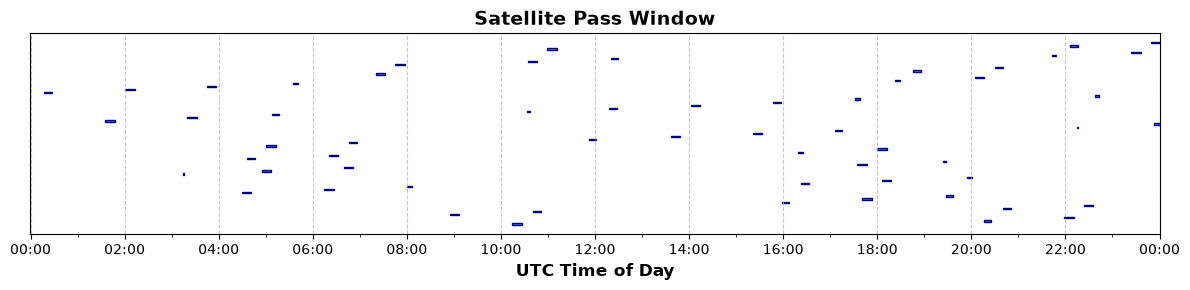

In [ ]:
# Visualization of valid passes generated from ai.

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
 
def get_all_pass_intervals(satellite: EarthSatellite, locations: list, altitude_degrees: float = 10.0) -> dict:
    """
    Scans a time window across multiple locations and returns a dictionary 
    mapping each location name to its list of pass intervals: 
    {'StationName': [("HH:MM:SS", "HH:MM:SS"), ...], ...}
    """

    t_start: Time = ts.now() - 1
    t_end: Time =ts.now() + 1
    all_intervals = []
    
    for name, site in locations:
        t, events = satellite.find_events(site, t_start, t_end, altitude_degrees=altitude_degrees)        
        i = 0
        while i < len(events):
            if events[i] == 0:  # Rise event (AOS)
                rise_time = t[i]
                set_time = None
                
                # Look ahead for the matching set event (LOS)
                for j in range(i + 1, len(events)):
                    if events[j] == 2:  # Set event
                        set_time = t[j]
                        break
                
                if set_time is not None:
                    rise_str = rise_time.utc_strftime('%H:%M:%S')
                    set_str = set_time.utc_strftime('%H:%M:%S')
                    all_intervals.append((rise_str, set_str))
                    
            i += 1
        
    return all_intervals

raw_intervals = get_all_pass_intervals(calsphere_1, locations)
fig, ax = plt.subplots(figsize=(12, 3))

# Define reference 24-hour bounds (00:00 to 24:00)
base_date = datetime(2026, 1, 1, 0, 0, 0)
end_base_date = base_date + timedelta(days=1)

# Force X-axis to span the entire 24 hours strictly
ax.set_xlim(base_date, end_base_date)

for i, (start_str, end_str) in enumerate(raw_intervals):
    t_start = datetime.strptime(start_str, "%H:%M:%S")
    t_end = datetime.strptime(end_str, "%H:%M:%S")
    
    start_dt = base_date.replace(hour=t_start.hour, minute=t_start.minute, second=t_start.second)
    end_dt = base_date.replace(hour=t_end.hour, minute=t_end.minute, second=t_end.second)
    
    if end_dt <= start_dt:
        end_dt += timedelta(days=1)
        
    # Use timedelta directly for width so Matplotlib scales it correctly
    duration_timedelta = end_dt - start_dt
    
    # Plot horizontal pass bar
    ax.barh(i, width=duration_timedelta, left=start_dt, color='dodgerblue', edgecolor='navy', height=0.4)

# Format X-axis for a complete 24-hour cycle
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_minor_locator(mdates.HourLocator(interval=1))

ax.set_xlabel('UTC Time of Day', fontsize=12, fontweight='bold')
ax.set_yticks([]) # Hide y-axis ticks since there's only one pass
ax.set_title('Satellite Pass Window', fontsize=14, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()